In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Pr 1 Data-Profiler\Data\Raw\Customer.csv")

print("Original Dataset Shape:", df.shape)

df.head()

Original Dataset Shape: (2000, 17)


,order_id,customer_id,age,product_id,country,signup_date,last_purchase_date,cancellations_count,subscription_status,order_date,unit_price,quantity,purchase_frequency,preferred_category,product_name,category,gender
0,ORD5000,CUST1000,39,PROD200,Canada,1/7/2021,2/21/2023,0,active,8/20/2024,78.21,5,37,Sports,Football,Sports,Female
1,ORD5001,CUST1001,61,PROD201,USA,10/19/2020,12/8/2021,0,active,7/17/2025,64.02,8,35,Sports,Refrigerator,Home,Female
2,ORD5002,CUST1002,26,PROD202,Pakistan,6/10/2023,9/4/2023,3,cancelled,3/12/2025,604.14,2,44,Electronics,Hoodie,Clothing,Female
3,ORD5003,CUST1003,54,PROD203,India,7/30/2023,2/20/2024,4,paused,9/19/2024,84.66,4,1,Sports,Conditioner,Beauty,Male
4,ORD5004,CUST1004,50,PROD204,India,12/9/2020,9/14/2024,0,active,8/8/2024,62.66,7,35,Sports,Smartwatch,Electronics,Male


In [4]:
clean_df = df.copy()

print("Backup created successfully!")

Backup created successfully!


In [5]:
missing_percentage = (
    clean_df.isnull().sum() / len(clean_df)
) * 100

display(missing_percentage)

order_id               0.0
customer_id            0.0
age                    0.0
product_id             0.0
country                0.0
signup_date            0.0
last_purchase_date     0.0
cancellations_count    0.0
subscription_status    0.0
order_date             0.0
unit_price             0.0
quantity               0.0
purchase_frequency     0.0
preferred_category     0.0
product_name           0.0
category               0.0
gender                 0.0
dtype: float64

In [6]:
numerical_columns = clean_df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

In [8]:
# Identify categorical columns
categorical_columns = clean_df.select_dtypes(
    include=["object", "category", "str"]
).columns

# Handle missing values using mode
for column in categorical_columns:
    mode_value = clean_df[column].mode()

    if not mode_value.empty:
        clean_df[column] = clean_df[column].fillna(
            mode_value[0]
        )

In [9]:
print("Duplicates Before:", clean_df.duplicated().sum())

clean_df = clean_df.drop_duplicates()

print("Duplicates After:", clean_df.duplicated().sum())

Duplicates Before: 0
Duplicates After: 0


In [10]:
print(clean_df.dtypes)

order_id                   str
customer_id                str
age                      int64
product_id                 str
country                    str
signup_date                str
last_purchase_date         str
cancellations_count      int64
subscription_status        str
order_date                 str
unit_price             float64
quantity                 int64
purchase_frequency       int64
preferred_category         str
product_name               str
category                   str
gender                     str
dtype: object


In [11]:
if "LastPurchaseDate" in clean_df.columns:
    clean_df["LastPurchaseDate"] = pd.to_datetime(
        clean_df["LastPurchaseDate"],
        errors="coerce"
    )

In [13]:
# Remove leading and trailing spaces from string columns

for column in clean_df.select_dtypes(
    include=["object", "str"]
).columns:

    clean_df[column] = clean_df[column].str.strip()

In [14]:
if "Gender" in clean_df.columns:
    clean_df["Gender"] = clean_df["Gender"].str.title()

In [15]:
numerical_columns = clean_df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:

    Q1 = clean_df[column].quantile(0.25)
    Q3 = clean_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ]

    print(column, "Outliers:", len(outliers))

age Outliers: 0
cancellations_count Outliers: 0
unit_price Outliers: 186
quantity Outliers: 0
purchase_frequency Outliers: 0


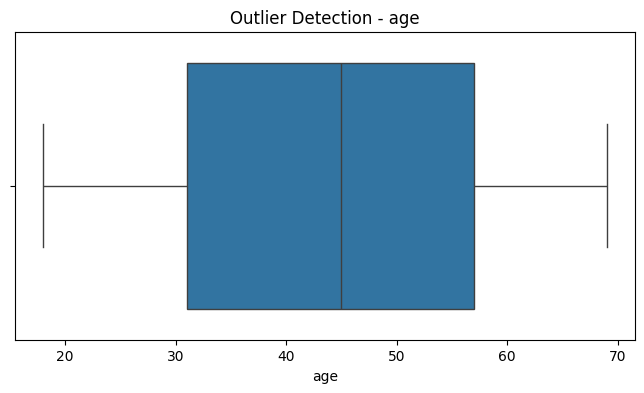

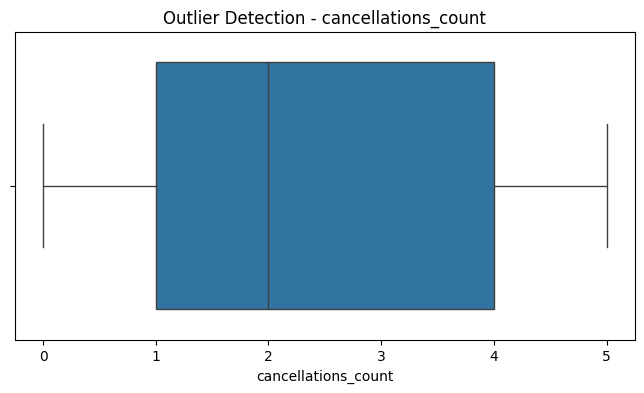

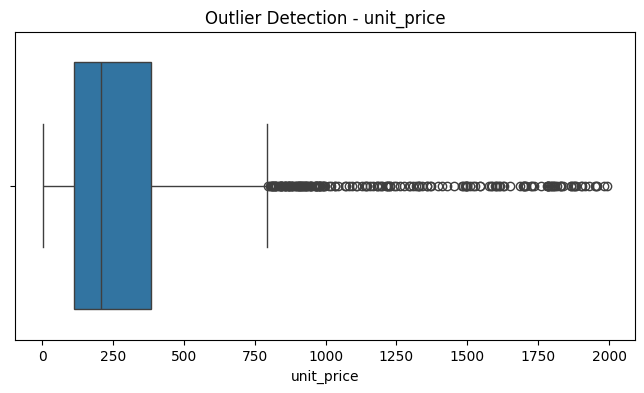

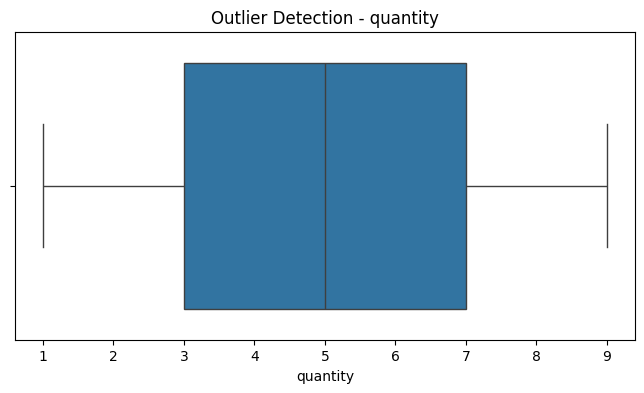

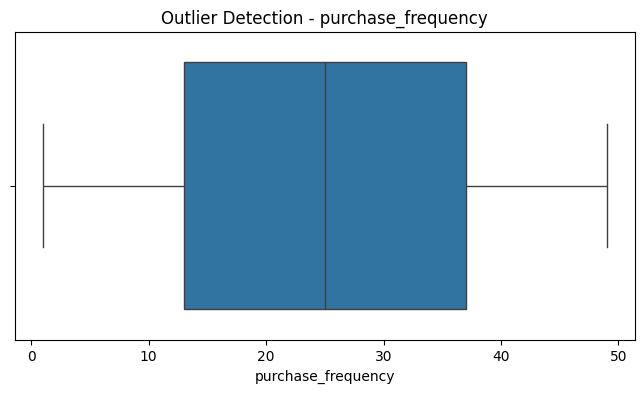

In [17]:
for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=clean_df[column])

    plt.title(f"Outlier Detection - {column}")

    plt.show()

In [19]:
print("Original Shape:", df.shape)

Original Shape: (2000, 17)


In [20]:
print("Cleaned Shape:", clean_df.shape)

Cleaned Shape: (2000, 17)


In [21]:
print("Remaining Missing Values:")
print(clean_df.isnull().sum().sum())

Remaining Missing Values:
0


In [22]:
print("Remaining Duplicates:")
print(clean_df.duplicated().sum())

Remaining Duplicates:
0


In [23]:
import os

os.makedirs("../Data/Processed", exist_ok=True)

clean_df.to_csv(
    "../Data/Processed/cleaned_customers.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
